# Evolution of the two-part layer-1 run

Same animation as `analysis_on_even_more_reduced.ipynb`, on the run from
**`train_l1_two_parts.py`**.

**The one difference between the two scripts.** Layer 1's noise-suppression block is split by KEY
token only, exactly like layer 2's A block — instead of into four quadrants:

| block | `train.py` | `train_l1_two_parts.py` |
|---|---|---|
| **L1 $W_{qk}$[0:8, 0:8]** | four 4×4 quadrants, **64 → 4 dof** | left 8×4, right 8×4, **64 → 2 dof** |
| L2 A [0:8, 0:8] | left 8×4, right 8×4, 64 → 2 | unchanged |
| L2 B [0:4, 108:112] | diagonal / off-diagonal, 16 → 2 | unchanged |
| L2 C [108:112, 108:112] | diagonal / off-diagonal, 16 → 2 | unchanged |
| L1 position block | untied, 9,900 free | unchanged |

Degrees of freedom **9,910 → 9,908**; free cells stay 10,060 in both.

**What it tests.** The four-quadrant version lets a *signal* query and a *noise* query apply
different vetoes to the same key. Two halves remove that — the veto depends only on the key's
token. `train.py` is its own control: four free quadrants can collapse to two if that is what the
loss wants, so if its `qsig` and `qnoi` values converge, this constraint costs nothing. Early
evidence says otherwise — in `train.py` the signal-query and noise-query rows took **opposite
signs**, which two halves cannot express.

**What tying does to the picture.** The tie is enforced on the full matrices — a gradient hook
replaces each group's gradient by its sum, and `retie()` re-averages after every step — so the
stored entries are already the single parameter *broadcast* across its group. Nothing has to be
expanded here: every cell of a group holds the same number and they move together, frame by frame.

Group boundaries are drawn in **black** over each tied panel. Values are the **raw entries of
$W_{qk}$** — no centering, no rescaling.

In [2]:
import os, json, glob, re
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from matplotlib.colors import SymLogNorm
from IPython.display import HTML, display
plt.rcParams['animation.embed_limit'] = 300

V, Vs, T = 8, 4, 100
D1, D2 = V + T, 2 * (V + T)          # 108, 216

RUN_PREFIX = 'tied2_'          # train_l1_two_parts.py tags its runs this way;
                               # train.py uses 'tied_', so the two never collide

def discover_run():
    '''the RUN_PREFIX run with the most epochs that has snapshots -- falls back to the newest'''
    cands = [d for d in glob.glob(f'runs/{RUN_PREFIX}*/')
             if glob.glob(os.path.join(d, 'snapmeta_*.json'))]
    if not cands:
        raise FileNotFoundError(
            f'no runs/{RUN_PREFIX}* has snapshots yet -- start train_l1_two_parts.py first.\n'
            f'  (runs present: {sorted(os.path.basename(d.rstrip("/")) for d in glob.glob("runs/*/"))})')
    def eps(d):
        m = re.search(r'_ep-(\d+)', d)
        return int(m.group(1)) if m else -1
    return max(cands, key=lambda d: (eps(d), os.path.getmtime(d))).rstrip('/')

RUN = discover_run()            # or set it yourself, e.g. RUN = 'runs/tied2_..._ep-500'
print(RUN, '\n')

def thresholds_present():
    '''read them off the files -- a run may use any --thresholds, not just 0.6/0.8/1.0'''
    out = []
    for p in glob.glob(f'{RUN}/snapmeta_x_*.json'):
        m = re.search(r'snapmeta_x_([0-9.]+)\.json$', p)
        if m:
            out.append(float(m.group(1)))
    return sorted(out)

THRS = thresholds_present()
if not THRS:
    raise FileNotFoundError(f'{RUN} has no snapmeta_x_*.json')
for _t in THRS:
    _m = json.load(open(f'{RUN}/snapmeta_x_{_t}.json'))
    _done = _m['w_rows_written'] >= _m['rows_allocated']
    print(f"  alpha={_t}: w={_m['w_rows_written']}/{_m['rows_allocated']}  g={_m['g_rows_written']}  "
          f"{'complete' if _done else 'STILL TRAINING -- cells below use what exists'}")

def aligned_losses(thr):
    '''train and test loss indexed by the weights they describe.

    train.py already evaluates BOTH after the step, so no shift is needed here -- unlike
    folder 18, where train_loss was the pre-step value and lagged test by one. `train_loss_pre`
    is kept in the metrics for exactly that comparison.
    '''
    h = json.load(open(f'{RUN}/metrics_seed0_x_{thr}.json'))['history']
    return (np.asarray(h['step']), np.asarray(h['train_loss']), np.asarray(h['test_loss']),
            h['test_loss'][-1], h['step'][-1])

def group_map(meta, param, mask):
    '''full-shape int array: which tie group each cell belongs to (-1 = untied)'''
    gid = np.full(meta['shapes'][param], -1, dtype=int)
    pos = np.argwhere(mask)                       # i-th True cell, row-major -- the row layout
    for k, (_, idxs) in enumerate(sorted(meta.get('tie_groups', {}).get(param, {}).items())):
        for i in idxs:
            gid[tuple(pos[i])] = k
    return gid

def panel(ax, A, title, vmax, annot, gid=None):
    v = vmax if vmax > 0 else 1.0
    ax.imshow(A, cmap='RdBu_r', interpolation='nearest',
              norm=SymLogNorm(linthresh=v / 1e3, linscale=0.6, vmin=-v, vmax=v, base=10))
    if annot:
        lab = [['0' if z == 0 else (f'{z:.3g}' if abs(z) >= 0.01 else f'{z:.1e}') for z in row]
               for row in A]
        wid = max(len(x) for row in lab for x in row)
        fs = (12.5 if A.shape[0] <= Vs else 6.4) * min(1.0, 5.0 / wid)
        for i in range(A.shape[0]):
            for j in range(A.shape[1]):
                ax.text(j, i, lab[i][j], ha='center', va='center', fontsize=fs,
                        color='white' if abs(A[i, j]) > v / 3 else 'black')
        if A.shape[0] <= Vs:
            ax.set_xticks(range(A.shape[1])); ax.set_yticks(range(A.shape[0]))
            ax.set_xticklabels([f'k{q}' for q in range(A.shape[1])], fontsize=8)
            ax.set_yticklabels([f'q{q}' for q in range(A.shape[0])], fontsize=8)
            ax.tick_params(length=0)
        else:
            ax.set_xticks([]); ax.set_yticks([])
    else:
        ax.set_xticks([]); ax.set_yticks([])
    if gid is not None:                       # outline the tie groups: one parameter each
        for i in range(gid.shape[0]):
            for j in range(gid.shape[1]):
                if j + 1 < gid.shape[1] and gid[i, j] != gid[i, j + 1]:
                    ax.plot([j + .5, j + .5], [i - .5, i + .5], color='k', lw=2.2)
                if i + 1 < gid.shape[0] and gid[i, j] != gid[i + 1, j]:
                    ax.plot([j - .5, j + .5], [i + .5, i + .5], color='k', lw=2.2)
    ax.set_title(f'{title}\n$\\|\\cdot\\|_F$ {np.linalg.norm(A):.4g}', fontsize=9)

runs/tied2_opt-adam_lr-1.0_init-zeros_wov-fixed_blocks-relevant_readout-bias_ep-100 

  alpha=0.5: w=101/101  g=100  complete
  alpha=0.6: w=101/101  g=100  complete
  alpha=0.7: w=101/101  g=100  complete
  alpha=0.8: w=101/101  g=100  complete
  alpha=0.9: w=101/101  g=100  complete
  alpha=1.0: w=101/101  g=100  complete


## The animation

`ANIM_FROM` / `ANIM_TO` are epochs, both inclusive. Colour scales are fixed across the frames
*shown*, so a late window is scaled to itself — which is what makes small late changes visible,
and also means two windows are not comparable by colour.

In [ ]:
ANIM_THR  = 0.6      # any alpha listed above
ANIM_FROM = 50        # first epoch  (inclusive)
ANIM_TO   = 100       # last  epoch  (inclusive)
LOSS_ROW_H = 1.24     # height of the loss row, in units of one matrix row (0.62 = old)
ANIM_DPI   = 88       # six panels wide now -- drop this if the notebook feels heavy

# A 10x10 window from the MIDDLE of layer 1's 100x100 position block, blown up to a panel
# of its own and placed third, next to the full block. The full 100x100 is 9,900 near-identical
# ramp rows in which nothing is legible; this window is where the ramp actually lives -- it
# straddles the causal diagonal, so the decay with distance is visible cell by cell.
ZOOM_AT, ZOOM_N = 45, 10                      # position block rows/cols [45:55]
ZOOM = slice(V + ZOOM_AT, V + ZOOM_AT + ZOOM_N)

# the six panels: (param, row slice, col slice, label, annotate?)
CUT = [('layer1.W_qk', slice(0, V),        slice(0, V),        'L1 tok x tok',     True),
       ('layer1.W_qk', slice(V, D1),       slice(V, D1),       'L1 pos x pos',     False),
       ('layer1.W_qk', ZOOM,               ZOOM,
        f'L1 pos x pos  [{ZOOM_AT}:{ZOOM_AT + ZOOM_N}]  zoom',                     True),
       ('layer2.W_qk', slice(0, V),        slice(0, V),        'L2 A  noise suppr.', True),
       ('layer2.W_qk', slice(0, Vs),       slice(D1, D1 + Vs), 'L2 B  induction',  True),
       ('layer2.W_qk', slice(D1, D1 + Vs), slice(D1, D1 + Vs), 'L2 C  state',      True)]

def animate(thr, first=0, last=50, interval=450):
    mp = f'{RUN}/snapmeta_x_{thr}.json'
    if not os.path.exists(mp):
        raise FileNotFoundError(f'no snapshots for alpha={thr} in {RUN}')
    mt = json.load(open(mp))
    kmax = min(mt['w_rows_written'] - 1, mt['g_rows_written'] - 1)   # step k needs w[k] AND g[k]
    a, b = max(0, int(first)), min(int(last), kmax)
    if b < a:
        raise ValueError(f'empty range [{first}, {last}] -> [{a}, {b}]; '
                         f'this run has steps 0..{kmax} for alpha={thr}')
    if b < int(last):
        print(f'alpha={thr}: only steps 0..{kmax} recorded so far -> showing [{a}, {b}]')
    n = b - a + 1
    print(f'alpha={thr}: epochs {a}..{b}   ({n} frames)')

    Mk = {p: np.load(f'{RUN}/mask_{p}_x_{thr}.npy') for p in mt['params']}
    GID = {p: group_map(mt, p, Mk[p]) for p in mt['params']}
    Wf = {p: np.asarray(np.load(f'{RUN}/w_{p}_x_{thr}.npy', mmap_mode='r')[a:b + 1])
          for p in mt['params']}
    Gf = {p: np.asarray(np.load(f'{RUN}/g_{p}_x_{thr}.npy', mmap_mode='r')[a:b + 1])
          for p in mt['params']}

    def blocks(src, p, rs, cs):
        '''raw entries -- already the tied parameter broadcast over its group'''
        out = np.empty((n, rs.stop - rs.start, cs.stop - cs.start))
        for k in range(n):
            A = np.zeros(mt['shapes'][p]); A[Mk[p]] = src[p][k]; out[k] = A[rs, cs]
        return out

    Ws = [blocks(Wf, p, rs, cs) for p, rs, cs, _, _ in CUT]
    Gs = [blocks(Gf, p, rs, cs) for p, rs, cs, _, _ in CUT]
    vw = [float(np.abs(x).max()) for x in Ws]
    vg = [float(np.abs(x).max()) for x in Gs]
    gids = [GID[p][rs, cs] if an else None for p, rs, cs, _, an in CUT]

    st, tr, te, fin, nlast = aligned_losses(thr)
    st, tr, te = st[a:b + 1], tr[a:b + 1], te[a:b + 1]

    nb_ = len(CUT)
    # Three rows. The loss curve is no longer a narrow column on the right: it gets its own
    # row underneath both matrix rows, stretched across the full width, with the same panel
    # height it had before (LOSS_ROW_H is in units of one matrix row).
    f = plt.figure(figsize=(4.6 * nb_, 9.2 + 4.6 * LOSS_ROW_H + 1.55), dpi=ANIM_DPI)
    g = f.add_gridspec(3, nb_, height_ratios=[1, 1, LOSS_ROW_H], wspace=0.10, hspace=0.16)
    ax = np.array([[f.add_subplot(g[r, c_]) for c_ in range(nb_)] for r in range(2)])
    al = f.add_subplot(g[2, :])
    f.subplots_adjust(top=0.92, bottom=0.06, left=0.025, right=0.99)

    def dr(i_):
        ep = a + i_
        for a_ in ax.ravel():
            a_.clear()
        for j_, (_, _, _, ttl, an) in enumerate(CUT):
            panel(ax[0][j_], Ws[j_][i_], f'W  {ttl}', vw[j_], an, gids[j_])
            panel(ax[1][j_], Gs[j_][i_], f'grad  {ttl}', vg[j_], an, gids[j_])
        al.clear()
        al.plot(st, tr, color='#1f77b4', lw=1.8, label='train')
        al.plot(st, te, color='#ff7f0e', lw=1.4, ls='--', label='test')
        al.axvline(ep, color='k', lw=1.1, alpha=0.65)
        al.plot([ep], [tr[i_]], 'o', color='#1f77b4', ms=8, zorder=5)
        al.plot([ep], [te[i_]], 'o', color='#ff7f0e', ms=8, zorder=5)
        al.annotate(f'epoch {ep}\ntrain {tr[i_]:.5f}\ntest  {te[i_]:.5f}',
                    xy=(0.96, 0.95), xycoords='axes fraction', ha='right', va='top',
                    fontsize=8.5, family='monospace',
                    bbox=dict(boxstyle='round,pad=0.4', fc='white', ec='0.7', alpha=0.9))
        al.set_xlim(a - 0.5, b + 0.5)
        al.set_xlabel('optimizer step (= epoch)', fontsize=9)
        al.set_ylabel('cross entropy', fontsize=9); al.tick_params(labelsize=8)
        al.set_title(f'loss over epochs {a}..{b}\n(run ends at {fin:.5f} after {nlast})',
                     fontsize=9)
        al.grid(alpha=0.3); al.legend(fontsize=8, loc='lower left')
        note = '   --  zero init: W all zero, and layer 1 has NO gradient yet' if ep == 0 else ''
        f.suptitle(f'$\\alpha$={thr}   epoch {ep}   (range {a}..{b})   '
                   f'top: $W$ before update {ep+1};  middle: $g[{ep}]$ at those weights;  '
                   f'bottom: the loss'
                   f'   [black outlines = one tied parameter]{note}', fontsize=13)
        return []

    an_ = animation.FuncAnimation(f, dr, frames=n, interval=interval, blit=False)
    plt.close(f)
    html = an_.to_jshtml()
    print(f'  animation {len(html) / 1e6:.1f} MB   ({nb_} panels x 2 rows + loss row)')
    return HTML(html)

display(animate(ANIM_THR, ANIM_FROM, ANIM_TO))

alpha=0.6: only steps 0..99 recorded so far -> showing [50, 99]
alpha=0.6: epochs 50..99   (50 frames)


---

# Why GD's two diagonals come out nearly equal

Layer 2 decides which earlier keys to attend to, and two blocks vote on it:

- **B** = `W_qk2[0:4, 108:112]`, the query's own **token** against each key's retrieved state.
  It votes *"attend to keys whose state equals my own token."*
- **C** = `W_qk2[108:112, 108:112]`, the query's **retrieved state** against the same key
  states. It votes *"attend to keys whose state equals the previous state $\sigma_t$."*

At a **noise** query, B is switched off — its rows only cover signal tokens 0–3 — so C decides
alone. At a **signal** query the two genuinely conflict, and B has to win.

The construction settles that by making B twenty times larger (contrast **100** against **5**).
GD learns **10.4** against **6.2**, a ratio of **1.7**, and loses nothing. Why?

### Because the softmax subtracts; it never divides

Write each block as its centered contrast $c = \text{diag} - \text{off}$ (the only thing about a
$4\times4$ block the softmax can see — a constant added to a whole row is the gauge of §8.7).
Partition the keys by their retrieved state $\sigma_j$ and add up both blocks:

| key group | from B | from C | total |
|---|---|---|---|
| $\sigma_j = x_t$ — **correct** | $+B/2$ | $-c/2$ | $+(B-c)/2$ |
| $\sigma_j = \sigma_t$ — the rival | $-B/2$ | $+c/2$ | $-(B-c)/2$ |
| neither | $-B/2$ | $-c/2$ | $-(B+c)/2$ |

The correct key beats the rival by exactly $B - c$. **A difference, not a ratio.** The
construction gets $100-5=95$; GD gets $10.4-6.2=4.2$ — and 4.2 logits is already 68:1 odds,
which is 98.8% of the attention mass.

So there are two independent requirements, and neither is a ratio:

$$c \gtrsim 4 \quad\text{(noise queries can route at all)}\qquad
B - c \gtrsim 4 \quad\text{(signal queries still beat the rival)}$$

"Make C negligible next to B" is **sufficient** but not **necessary**. The construction had to
set $B=100$ for an unrelated reason — $B$ doubles as the veto depth, and §8.6 says keep
$B \ge K$ — and the 20:1 ratio fell out as a side effect.

### The three figures

1. **The two walls.** Sweep $c$ with $B$ held fixed, inside both models, splitting the CE by
   query type. A wide plateau with a wall at each end; the signal-query curve is flat in $c$
   until $B-c$ collapses, the noise-query curve is flat until $c$ collapses.
2. **The $(B,c)$ plane.** If a ratio were the criterion the good region would be a wedge
   through the origin — a straight line in log-log. It is a *diagonal band* whose edges are
   $c=4$ and $B-c=5$, with the 20:1 line cutting across it.
3. **Across $\alpha$.** $c$ shrinks as noise gets rarer and hits exactly 0 at $\alpha=1$, where
   there are no noise queries for it to serve — and a sigmoid of the margin tracks the measured
   attention mass. The printed table compares the nominal margins with the logit gap actually
   present in the model; the nominal numbers are a good but imperfect approximation, because
   layer 1 hands over an estimate of the state (peak 0.93) rather than a one-hot.

Everything below re-derives the construction and re-loads the trained weights, so this section
depends only on the setup cell at the top.


In [5]:
# ---------------------------------------------------------------- section 3 setup
# Everything this section needs. Layer 1 is untouched by the sweeps below, so its output is
# computed ONCE per model and the (b, c) scan only redoes layer 2 -- which makes a 150-point
# scan of the plane cost about as much as two forward passes.
import sys, torch
import torch.nn.functional as F

sys.path.insert(0, os.path.abspath('.'))
import train_l1_two_parts as MOD

TOKEN_START = 50       # the scored window is [50:100)
N_EVAL = 2000          # test sequences used for every CE below (10000 available)
CHUNK  = 1000
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
SDq    = D1 ** 0.5     # entries are logits * sqrt(108)
print('device', DEVICE, '  sequences', N_EVAL)

# the construction, centered about zero -- identical to section 3 of folder 18's notebook
LAM, KIND, BVETO, CAP = 20.0, 100.0, 100.0, 5

def construction_qk(k_ind=KIND, c_diag=KIND / 40, c_off=-KIND / 40):
    '''(W_qk layer 1, W_qk layer 2) for the hand construction, in ENTRY units.

    c_diag / c_off are the state block's two values, in LOGIT units -- the only knobs the
    sweeps below turn. Defaults +2.5 / -2.5 reproduce the construction exactly.
    '''
    T1 = np.zeros((D1, D1))
    T1[0:Vs, :] = +BVETO / 2                       # signal key tokens  +50
    T1[Vs:V, :] = -BVETO / 2                       # noise  key tokens  -50
    mid = LAM + 50.0
    for tq in range(T):
        for tk in range(T):
            if tq - tk > 0:
                T1[V + tk, V + tq] = mid - LAM * min(tq - tk, CAP)
    W1 = (np.eye(D1) * SDq).T @ T1.T
    W2 = np.zeros((D2, D2))
    W2[0:V, 0:Vs] = SDq * (+BVETO / 2)             # layer-2 noise suppression
    W2[0:V, Vs:V] = SDq * (-BVETO / 2)
    W2[0:Vs, D1:D1 + Vs] = SDq * (-k_ind / 2)      # B  induction
    np.fill_diagonal(W2[0:Vs, D1:D1 + Vs], SDq * (+k_ind / 2))
    W2[D1:D1 + Vs, D1:D1 + Vs] = SDq * c_off       # C  state
    np.fill_diagonal(W2[D1:D1 + Vs, D1:D1 + Vs], SDq * c_diag)
    return W1, W2

def contrast(A):
    '''diagonal minus off-diagonal -- the only thing about a 4x4 block the softmax can see'''
    return float(np.diag(A).mean() - A[~np.eye(A.shape[0], dtype=bool)].mean())

def thr_tag(t):
    '''the exact string the run files use -- alpha 1.0 is written "1.0" on disk, not "1"'''
    for p in glob.glob(f'{RUN}/snapmeta_x_*.json'):
        s = re.search(r'snapmeta_x_([0-9.]+)\.json$', p).group(1)
        if abs(float(s) - float(t)) < 1e-9:
            return s
    raise FileNotFoundError(f'{RUN} has no threshold {t}; present: {thresholds_present()}')

def gd_weights(thr):
    sd = torch.load(f'{RUN}/model_final_seed0_x_{thr_tag(thr)}.pth',
                    map_location='cpu', weights_only=False)
    return sd['layer1.W_qk'].numpy(), sd['layer2.W_qk'].numpy()

def gd_bc(thr):
    '''GD's induction and state contrasts at this threshold, in logit units'''
    _, W2 = gd_weights(thr)
    return (contrast(W2[0:Vs, D1:D1 + Vs] / SDq),
            contrast(W2[D1:D1 + Vs, D1:D1 + Vs] / SDq))

# ------------------------------------------------------------------ the fast (b, c) machinery
_CAUSAL = torch.triu(torch.ones(T, T, device=DEVICE) * float('-inf'), diagonal=0)
_CAUSAL[0, 0] = 0.0            # position 0 has no earlier key

@torch.no_grad()
def precompute(W1, W2, thr):
    '''Run layer 1 once; reduce layer 2 to  score = base + b*PB + c*PC.

    Writing the centered blocks as  Bmat = b*I - (b/2)*J  makes the query's contribution
    linear in b and c, so the whole (b, c) plane is three fixed tensors and a weighted sum.
    '''
    d = MOD.load_data('test', thr_tag(thr))
    x = d['x'][:N_EVAL].to(DEVICE)
    y = d['y'][:N_EVAL].to(DEVICE)
    t1 = torch.as_tensor(W1, dtype=torch.float32, device=DEVICE)
    A2 = torch.as_tensor(W2[0:V, 0:V] / SDq, dtype=torch.float32, device=DEVICE)
    packs = []
    for i in range(0, N_EVAL, CHUNK):
        xb = x[i:i + CHUNK]
        n = xb.shape[0]
        tok = F.one_hot(xb, V).float()
        pos = F.one_hot(torch.arange(T, device=DEVICE), T).float().unsqueeze(0).expand(n, -1, -1)
        s = torch.cat([tok, pos], -1)
        a1 = F.softmax(torch.bmm(s @ t1, s.transpose(1, 2)) / SDq + _CAUSAL, -1)
        st = torch.bmm(a1, tok)                       # layer 1's retrieved state, 8 wide
        qts, qs, ks = tok[..., :Vs], st[..., :Vs], st[..., :Vs]
        outer = lambda u, v: u.sum(-1, keepdim=True) * v.sum(-1).unsqueeze(1)
        packs.append(dict(
            kt=tok,
            base=torch.bmm(tok @ A2, tok.transpose(1, 2)),
            PB=torch.bmm(qts, ks.transpose(1, 2)) - outer(qts, ks) / 2,
            PC=torch.bmm(qs,  ks.transpose(1, 2)) - outer(qs,  ks) / 2,
            y=y[i:i + CHUNK, TOKEN_START:T],
            sig=(xb[:, TOKEN_START:T] < Vs)))
    return packs, MOD.readout_bias(float(thr), DEVICE)

@torch.no_grad()
def ce_bc(packs, bias, b, c):
    '''(CE over all scored positions, CE at signal queries, CE at noise queries)'''
    tot = []
    for p in packs:
        sc = p['base'] + b * p['PB'] + c * p['PC'] + _CAUSAL
        out = torch.bmm(F.softmax(sc, -1), p['kt'])[:, TOKEN_START:T]
        q = out + bias
        q = q / q.sum(-1, keepdim=True)
        tot.append((-torch.log(q.gather(-1, p['y'].unsqueeze(-1)).squeeze(-1).clamp_min(1e-30)),
                    p['sig']))
    L = torch.cat([t[0].reshape(-1) for t in tot])
    S = torch.cat([t[1].reshape(-1) for t in tot])
    f = lambda m: float(L[m].mean()) if bool(m.any()) else float('nan')
    return float(L.mean()), f(S), f(~S)

print('ready')

device cuda   sequences 2000
ready


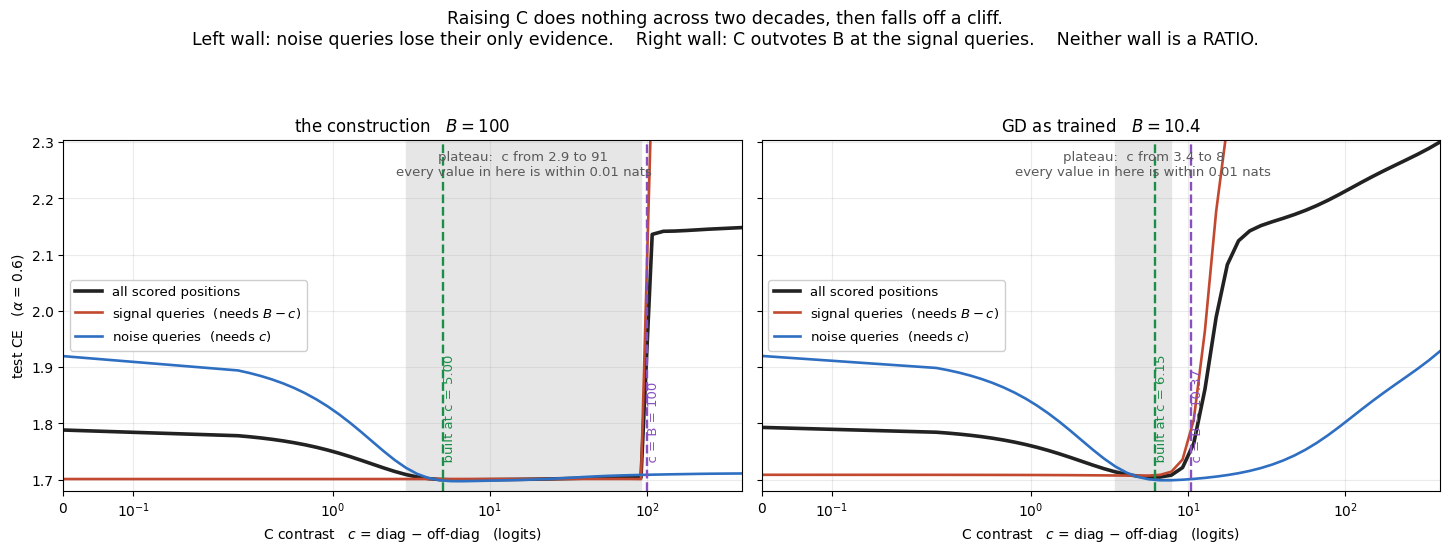

In [6]:
# ---------------------------------------------------------------- figure 1: the two walls
# Raise C's diagonal and lower its off-diagonal together -- that is exactly raising the
# contrast c = diag - off. Run inside the construction (B = 100) and inside GD (B ~ 10).
FIG1_THR = 0.6
CS = np.concatenate([[0.0], np.geomspace(0.25, 400, 46)])

def wall_sweep(W1, W2, thr, b):
    packs, bias = precompute(W1, W2, thr)
    return np.array([ce_bc(packs, bias, b, c) for c in CS])      # (len(CS), 3)

b_gd, c_gd = gd_bc(FIG1_THR)
curves = [('the construction   $B = 100$', *construction_qk(), BVETO, KIND / 40 * 2),
          (f'GD as trained   $B = {b_gd:.1f}$', *gd_weights(FIG1_THR), b_gd, c_gd)]

fig, axes = plt.subplots(1, 2, figsize=(14.6, 5.6), sharey=True)
for ax, (name, W1, W2, b, c_native) in zip(axes, curves):
    R = wall_sweep(W1, W2, FIG1_THR, b)
    ymin = R[:, 0].min()
    good = CS[R[:, 0] <= ymin + 0.01]                            # within 0.01 nats of the best
    ax.set_xscale('symlog', linthresh=0.25)
    ax.set_xlim(0, 400); ax.set_ylim(ymin - 0.025, ymin + 0.60)
    ax.axvspan(good.min(), good.max(), color='0.90', zorder=0)
    for k, (lab, col, lw) in enumerate([('all scored positions', '#222222', 2.6),
                                        ('signal queries  (needs $B-c$)', '#c2492f', 1.9),
                                        ('noise queries  (needs $c$)', '#2f6fc2', 1.9)]):
        ax.plot(CS, R[:, k], color=col, lw=lw, label=lab)
    xt = ax.get_xaxis_transform()                                # x in data, y in axes fraction
    for xv, col, lab, yf in ((c_native, '#1a8f4a', f'built at c = {c_native:.2f}', 0.06),
                             (b, '#8a4fbf', f'c = B = {b:.4g}', 0.06)):
        ax.axvline(xv, color=col, ls='--', lw=1.7)
        ax.text(xv, yf, f'  {lab}', transform=xt, rotation=90, color=col,
                fontsize=9.5, va='bottom', ha='left')
    ax.text(np.sqrt(good.min() * good.max()), 0.97,
            f'plateau:  c from {good.min():.1f} to {good.max():.0f}\n'
            f'every value in here is within 0.01 nats',
            transform=xt, ha='center', va='top', fontsize=9.5, color='0.35')
    ax.set_xlabel('C contrast   $c$ = diag $-$ off-diag   (logits)')
    ax.set_title(name, fontsize=12)
    ax.grid(alpha=0.25, which='both')
    ax.legend(loc='center left', fontsize=9.5, framealpha=0.95)
axes[0].set_ylabel(f'test CE   ($\\alpha$ = {FIG1_THR})')
fig.suptitle('Raising C does nothing across two decades, then falls off a cliff.\n'
             'Left wall: noise queries lose their only evidence.    Right wall: C outvotes B '
             'at the signal queries.    Neither wall is a RATIO.', fontsize=12.5)
fig.tight_layout(rect=[0, 0, 1, 0.91])
plt.show()

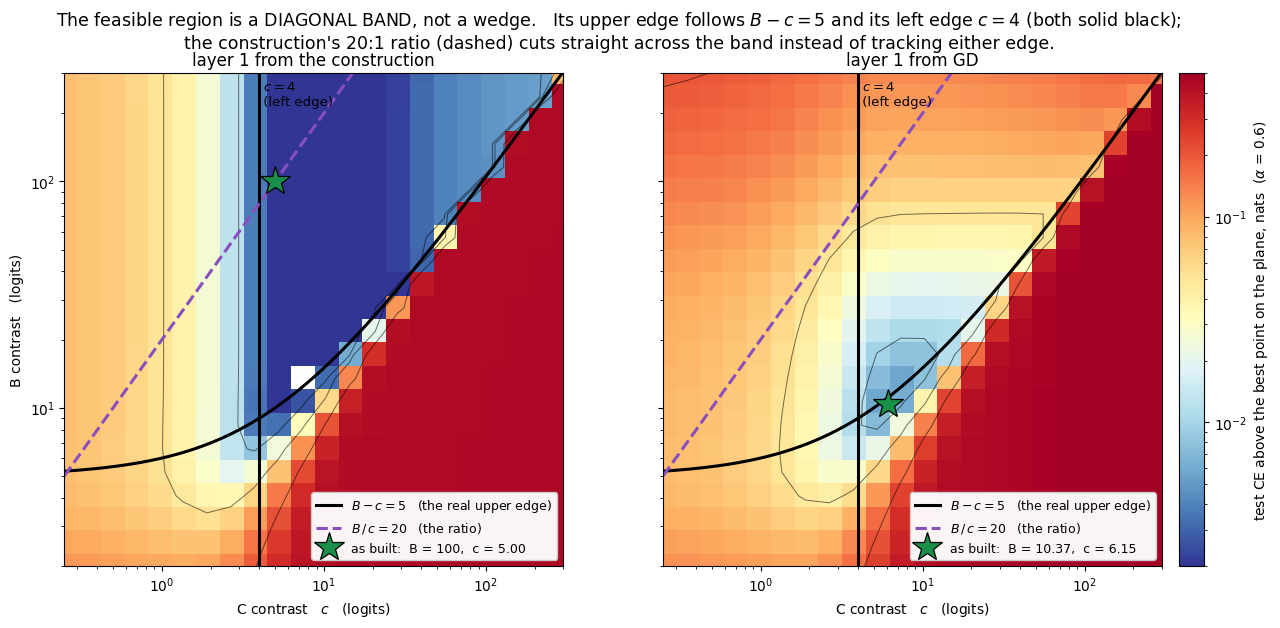

In [7]:
# ---------------------------------------------------------------- figure 2: the (B, c) plane
# If the requirement were a RATIO, the good region would be a wedge through the origin -- a
# straight line of slope 1 in log-log. If it is two additive margins, the good region is bounded
# on the left by  c = const  and above by  B - c = const.  Those two shapes look nothing alike.
from matplotlib.colors import LogNorm

FIG2_THR = 0.6
BS  = np.geomspace(2.0, 300.0, 22)      # ~60 s for both panels at N_EVAL = 2000
CSP = np.geomspace(0.25, 300.0, 22)

def plane(W1, W2, thr):
    packs, bias = precompute(W1, W2, thr)
    return np.array([[ce_bc(packs, bias, b, c)[0] for c in CSP] for b in BS])

b_gd, c_gd = gd_bc(FIG2_THR)
panels = [('layer 1 from the construction', *construction_qk(), BVETO, KIND / 40 * 2),
          ('layer 1 from GD', *gd_weights(FIG2_THR), b_gd, c_gd)]
G0 = plane(*panels[0][1:3], FIG2_THR)
G1 = plane(*panels[1][1:3], FIG2_THR)
vmin = min(G0.min(), G1.min())

fig, axes = plt.subplots(1, 2, figsize=(14.8, 6.4), sharey=True)
for ax, (name, _, _, bn, cn), G in zip(axes, panels, [G0, G1]):
    E = G - vmin                                     # nats above the best point on the plane
    im = ax.pcolormesh(CSP, BS, E, cmap='RdYlBu_r', shading='nearest',
                       norm=LogNorm(vmin=2e-3, vmax=5e-1))
    ax.contour(CSP, BS, E, levels=[0.01, 0.05, 0.2], colors='k', linewidths=0.7, alpha=0.55)
    g = np.geomspace(0.25, 300, 400)
    ax.plot(g, g + 5.0, color='k', lw=2.2, label='$B - c = 5$   (the real upper edge)')
    ax.axvline(4.0, color='k', lw=2.2)
    ax.plot(g, 20 * g, color='#8a4fbf', lw=2.2, ls='--', label='$B\\,/\\,c = 20$   (the ratio)')
    ax.plot([cn], [bn], marker='*', ms=22, color='#1a8f4a', mec='k', mew=0.9, ls='none',
            label=f'as built:  B = {bn:.4g},  c = {cn:.2f}', zorder=5)
    ax.text(4.0, 0.985, ' $c = 4$\n (left edge)', transform=ax.get_xaxis_transform(),
            fontsize=9.5, va='top', ha='left')
    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_xlim(CSP[0], CSP[-1]); ax.set_ylim(BS[0], BS[-1])
    ax.set_xlabel('C contrast   $c$   (logits)')
    ax.set_title(name, fontsize=12)
    ax.legend(loc='lower right', fontsize=9, framealpha=0.96)
axes[0].set_ylabel('B contrast   (logits)')
fig.colorbar(im, ax=axes, fraction=0.028, pad=0.015,
             label=f'test CE above the best point on the plane, nats  ($\\alpha$ = {FIG2_THR})')
fig.suptitle('The feasible region is a DIAGONAL BAND, not a wedge.   Its upper edge follows '
             '$B-c=5$ and its left edge $c=4$ (both solid black);\nthe construction\'s 20:1 '
             'ratio (dashed) cuts straight across the band instead of tracking either edge.',
             fontsize=12.5)
plt.show()

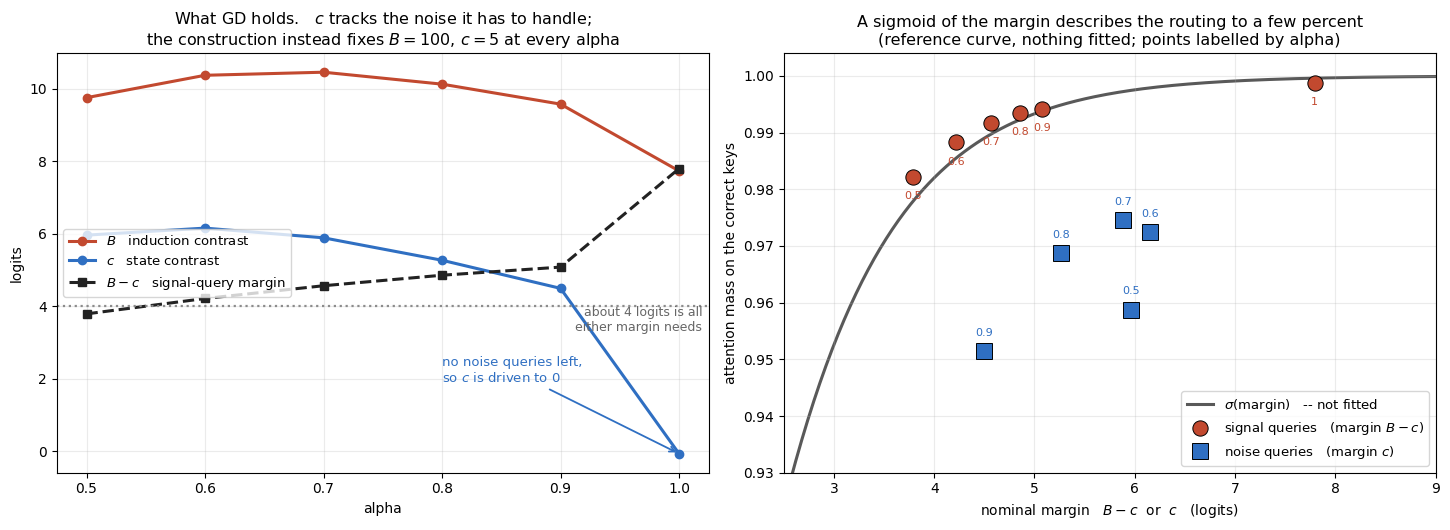

Nominal margin vs the logit gap the softmax really sees. The nominal numbers order
things correctly and get the scale about right, but they are an approximation: the
signal-query gap runs ~1.4x nominal, the noise-query gap ~0.7x, because layer 1 hands
over an ESTIMATE of the state (peak 0.93) rather than a one-hot, and because each
group holds many keys, not one.

 alpha       B       c |                  signal queries |                   noise queries
                       |   nom B-c    actual       mass |     nom c    actual       mass
--------------------------------------------------------------------------------------------
   0.5   9.751   5.961 |     3.790     5.972     0.9822 |     5.961     3.934     0.9587
   0.6  10.368   6.154 |     4.214     6.461     0.9883 |     6.154     4.187     0.9724
   0.7  10.453   5.887 |     4.566     6.670     0.9917 |     5.887     4.109     0.9746
   0.8  10.124   5.268 |     4.855     6.865     0.9935 |     5.268     3.889     0.9687
   0

In [8]:
# ---------------------------------------------------------------- figure 3: across alpha
# The claim in one picture: the softmax sees two MARGINS, and both obey the same sigmoid.
#   signal queries -> correct attention mass = sigmoid(B - c)
#   noise  queries -> correct attention mass = sigmoid(c)
# Nothing is fitted; both margins are read straight off the trained weights.
@torch.no_grad()
def routing(thr):
    '''measured layer-2 attention mass on the correct key group, signal and noise queries'''
    W1, W2 = gd_weights(thr)
    x = MOD.load_data('test', thr_tag(thr))['x'][:N_EVAL].to(DEVICE)
    t1 = torch.as_tensor(W1, dtype=torch.float32, device=DEVICE)
    t2 = torch.as_tensor(W2, dtype=torch.float32, device=DEVICE)
    ms, mn, dx, dn = [], [], [], []
    for i in range(0, N_EVAL, CHUNK):
        xb = x[i:i + CHUNK]; n = xb.shape[0]
        tok = F.one_hot(xb, V).float()
        pos = F.one_hot(torch.arange(T, device=DEVICE), T).float().unsqueeze(0).expand(n, -1, -1)
        s = torch.cat([tok, pos], -1)
        a1 = F.softmax(torch.bmm(s @ t1, s.transpose(1, 2)) / SDq + _CAUSAL, -1)
        st = torch.bmm(a1, tok)                        # layer 1's retrieved state, 8 wide
        h1 = torch.cat([s, st, torch.zeros(n, T, T, device=DEVICE)], -1)
        a2 = F.softmax(torch.bmm(h1 @ t2, h1.transpose(1, 2)) / SDq + _CAUSAL, -1)
        kstate = st[..., :Vs].argmax(-1)               # each key's retrieved state
        # sigma_t = last signal token strictly BEFORE t -- the key group C points at
        sg = xb < Vs
        idx = torch.arange(T, device=DEVICE).view(1, -1).expand(n, -1)
        prev = torch.cat([torch.full((n, 1), -1, device=DEVICE),
                          torch.where(sg, idx, torch.full_like(idx, -1)).cummax(1).values[:, :-1]], 1)
        sigma = torch.where(prev >= 0, xb.gather(1, prev.clamp_min(0)), torch.full_like(xb, -1))
        w = slice(TOKEN_START, T)
        aw, issig = a2[:, w, :], sg[:, w]
        gx = xb[:, w].unsqueeze(-1) == kstate.unsqueeze(1)        # keys whose state is x_t
        gs = sigma[:, w].unsqueeze(-1) == kstate.unsqueeze(1)     # keys whose state is sigma_t
        ms.append((aw * gx).sum(-1)[issig]); mn.append((aw * gs).sum(-1)[~issig])
        # the gap the softmax really sees: best key in the group minus best key outside it
        sc = (torch.bmm(h1 @ t2, h1.transpose(1, 2)) / SDq)[:, w, :].double()
        valid = torch.isfinite(_CAUSAL[w, :]).unsqueeze(0)
        NEG = torch.tensor(-1e18, dtype=torch.float64, device=DEVICE)
        def gap(g, sel):
            gi, go = g & valid, (~g) & valid
            ok = gi.any(-1) & go.any(-1) & sel
            return (torch.where(gi, sc, NEG).max(-1).values
                    - torch.where(go, sc, NEG).max(-1).values)[ok]
        dx.append(gap(gx, issig)); dn.append(gap(gs, ~issig))
    ms, mn = torch.cat(ms), torch.cat(mn)
    f = lambda t: float(t.mean()) if t.numel() else np.nan
    return f(ms), f(mn), f(torch.cat(dx)), f(torch.cat(dn))

A  = np.array(THRS)
BC = np.array([gd_bc(t) for t in A])                   # (n_alpha, 2): B, c
RT = np.array([routing(t) for t in A])   # (n_alpha, 4): masses, then ACTUAL logit gaps
sigmoid = lambda z: 1.0 / (1.0 + np.exp(-z))

fig, axes = plt.subplots(1, 2, figsize=(14.6, 5.4))

ax = axes[0]
ax.plot(A, BC[:, 0], 'o-', color='#c2492f', lw=2.2, label='$B$   induction contrast')
ax.plot(A, BC[:, 1], 'o-', color='#2f6fc2', lw=2.2, label='$c$   state contrast')
ax.plot(A, BC[:, 0] - BC[:, 1], 's--', color='#222222', lw=2.2,
        label='$B - c$   signal-query margin')
ax.axhline(4.0, color='0.55', ls=':', lw=1.6)
ax.text(0.99, 4.0, '  about 4 logits is all\n  either margin needs', transform=ax.get_yaxis_transform(),
        fontsize=9, color='0.4', ha='right', va='top')
ax.annotate('no noise queries left,\nso $c$ is driven to 0', xy=(A[-1], BC[-1, 1]),
            xytext=(0.80, 1.9), fontsize=9.5, color='#2f6fc2',
            arrowprops=dict(arrowstyle='->', color='#2f6fc2', lw=1.3))
ax.set_xlabel('alpha'); ax.set_ylabel('logits'); ax.grid(alpha=0.25)
ax.set_title('What GD holds.   $c$ tracks the noise it has to handle;\n'
             'the construction instead fixes $B=100$, $c=5$ at every alpha', fontsize=11.5)
ax.legend(fontsize=9.5, loc='center left')

ax = axes[1]
z = np.linspace(0, 9, 300)
ax.plot(z, sigmoid(z), color='0.35', lw=2.2, zorder=1,
        label=r'$\sigma(\mathrm{margin})$   -- not fitted')
ok = ~np.isnan(RT[:, 1])
ax.plot(BC[:, 0] - BC[:, 1], RT[:, 0], 'o', ms=11, color='#c2492f', mec='k', mew=0.7,
        zorder=3, label='signal queries   (margin $B-c$)')
ax.plot(BC[ok, 1], RT[ok, 1], 's', ms=11, color='#2f6fc2', mec='k', mew=0.7,
        zorder=3, label='noise queries   (margin $c$)')
for i, t in enumerate(A):
    ax.annotate(f'{t:g}', (BC[i, 0] - BC[i, 1], RT[i, 0]), textcoords='offset points',
                xytext=(0, -16), ha='center', fontsize=8, color='#c2492f')
    if ok[i]:
        ax.annotate(f'{t:g}', (BC[i, 1], RT[i, 1]), textcoords='offset points',
                    xytext=(0, 11), ha='center', fontsize=8, color='#2f6fc2')
ax.set_xlim(2.5, 9); ax.set_ylim(0.93, 1.004)
ax.set_xlabel('nominal margin   $B-c$  or  $c$   (logits)')
ax.set_ylabel('attention mass on the correct keys')
ax.set_title('A sigmoid of the margin describes the routing to a few percent\n'
             '(reference curve, nothing fitted; points labelled by alpha)', fontsize=11.5)
ax.grid(alpha=0.25); ax.legend(fontsize=9.5, loc='lower right')
fig.tight_layout()
plt.show()

print('Nominal margin vs the logit gap the softmax really sees. The nominal numbers order')
print('things correctly and get the scale about right, but they are an approximation: the')
print('signal-query gap runs ~1.4x nominal, the noise-query gap ~0.7x, because layer 1 hands')
print('over an ESTIMATE of the state (peak 0.93) rather than a one-hot, and because each')
print('group holds many keys, not one.\n')
print(f'{"alpha":>6} {"B":>7} {"c":>7} | {"signal queries":>31} | {"noise queries":>31}')
print(f'{"":>6} {"":>7} {"":>7} | {"nom B-c":>9} {"actual":>9} {"mass":>10} '
      f'| {"nom c":>9} {"actual":>9} {"mass":>10}')
print('-' * 92)
for i, t in enumerate(A):
    nz = lambda v: '     --  ' if np.isnan(v) else f'{v:9.3f}'
    print(f'{t:>6g} {BC[i,0]:7.3f} {BC[i,1]:7.3f} | {BC[i,0]-BC[i,1]:9.3f} {RT[i,2]:9.3f} '
          f'{RT[i,0]:10.4f} | {BC[i,1]:9.3f} {nz(RT[i,3])} '
          f'{"     --   " if np.isnan(RT[i,1]) else f"{RT[i,1]:10.4f}"}')